In [20]:
# Numeric values and BPR (Bits Per Row)

# Assigning bits to different tokenization strategies on categorical data within
# a row borrows directly from bits-per-byte. Numerics data poses more
# challenges.

# Assigning bits to predicted numeric values requires handling (a) bin sizes (b)
# discrete vs continuous (c) centering and scaling of continuous predictions (d)
# clipping. This notebook walks through each of these scenarios.
 
# To demonstrate how each of these are handled, and their equivalency under
# certain assumptions, we consider the BPR for each modeling approach (bins,
# continuous, clipping) applied to a known outcome distribution of values with
# an "oracle" model for predictions. This demonstreates how BPR changes due to
# different numeric handling choices rather than through model fit or capacity.

# We pick an underlying distribution of values and then set the "output" to be
# the unbiased expectation of that distribution for the chosen numeric strategy.
# In orther words, if the true distribution is gaussian and we have 10 bins,
# each bin receives the predicted probability expected from the true value
# distribution.

# the following concepts are shown here:
# 1) bin count and spacing.
# 2) continuous values and centering/scaling transformations


In [21]:
# some imports
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad
import numpy as np

# value distribution
true_dist = stats.norm(50, 5)                # the distribution of true values
LO, HI = 20, 80                         # mean +/- 6 standard deviations
x = np.linspace(LO, HI, 2001)


# helper functiosn for laying out bins
def equal_width_edges(K):
    return np.linspace(LO, HI, K + 1)

def equal_probability_edges(K):
    return true_dist.ppf(np.linspace(true_dist.cdf(LO), true_dist.cdf(HI), K + 1))

# helper for plotting bins
def draw_bins(ax, edges, color):
    prob = np.diff(true_dist.cdf(edges))         # probability of each bin
    width = np.diff(edges)
    ax.stairs(prob / width, edges, color=color, lw=1.2)
    ax.plot(x, true_dist.pdf(x), color="black", lw=0.8, ls="--")

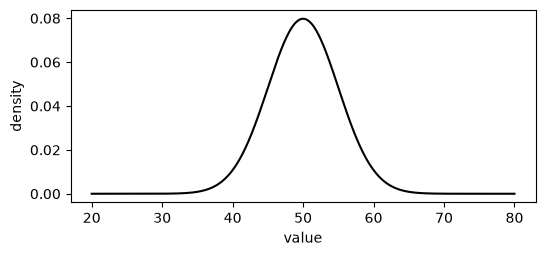

This is the true value distribution with mean 50 and standard deviation 5


In [22]:
# The true value distribution has mean of 50 and standard deviation of 5
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(x, true_dist.pdf(x), color="black")
ax.set_xlabel("value")
ax.set_ylabel("density")
plt.show()
print(f"This is the true value distribution with mean {50} and standard deviation {5}")


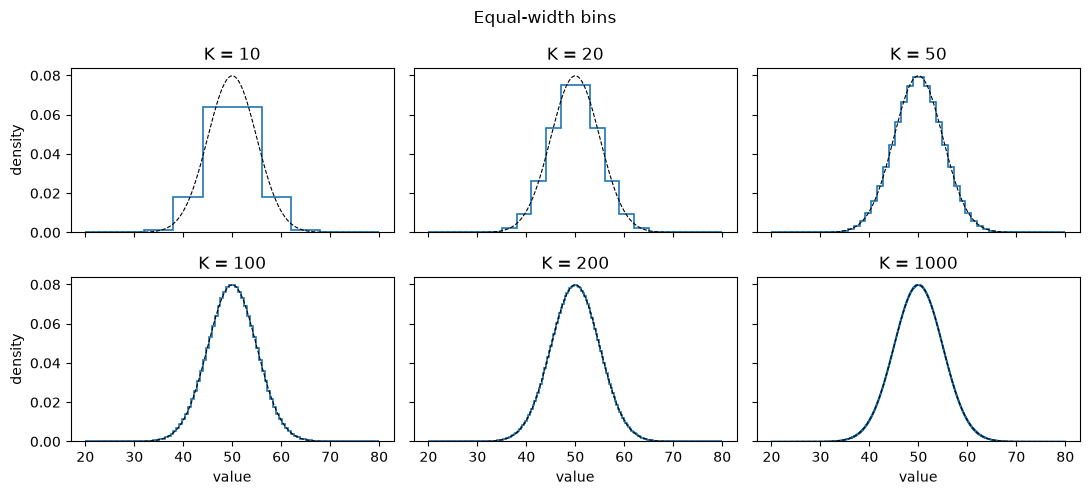

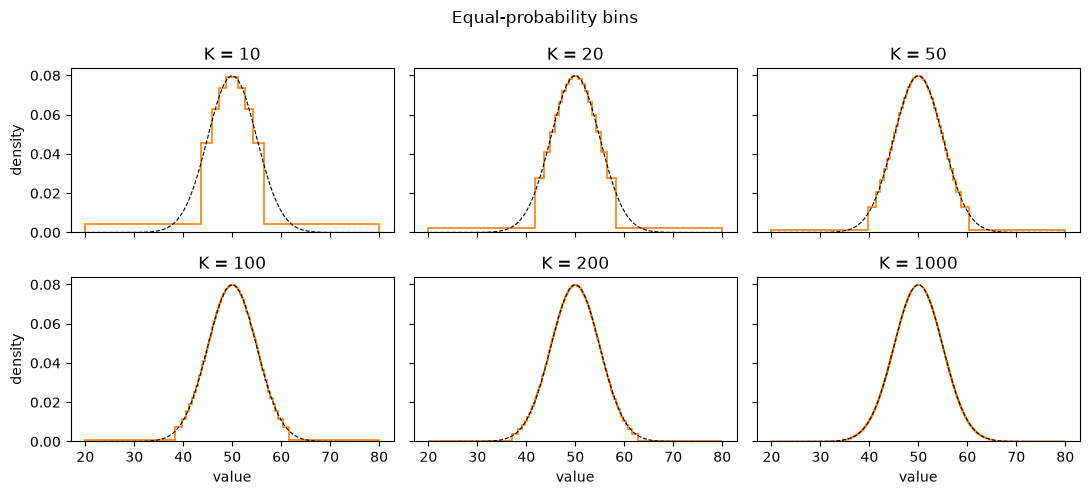

In [23]:
# 1a. BIN COUNT AND SPACING: INTRODUCTION

# Discretized number predictions divide the number line into K bins and assign a
# probability mass to each bin. This probability mass must be converted to a
# density to allow for comparison. Perplexity is not a valid comparison because
# a single numeric bin (-inf,inf) could have a next-token probabilty of 1 with
# no precision.

# Precision is therefore a function of bin count and how those bins are
# distributed relative to the underlying distribution.

# Bits per Row converts discrete distributions into a density by dividing each
# probability mass by the bin width

# Here are two methods of laying out bins:
#  1) equal probability: every bin has same number of values, narrow where
#     common, wide where rare
#  2) equal spacing: every bin has different number of values, more bins
#     allocated to rare values


# Bins overlayed on true value distribution
Ks = [10, 20, 50, 100, 200, 1000]
for name, make_edges, color in [
    ("Equal-width bins", equal_width_edges, "C0"),
    ("Equal-probability bins", equal_probability_edges, "C1"),
]:
    fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, sharey=True)
    for ax, K in zip(axes.flat, Ks):
        draw_bins(ax, make_edges(K), color)
        ax.set_title(f"K = {K}")
    for ax in axes[1]:
        ax.set_xlabel("value")
    for ax in axes[:, 0]:
        ax.set_ylabel("density")
    fig.suptitle(name)
    fig.tight_layout()
    plt.show()


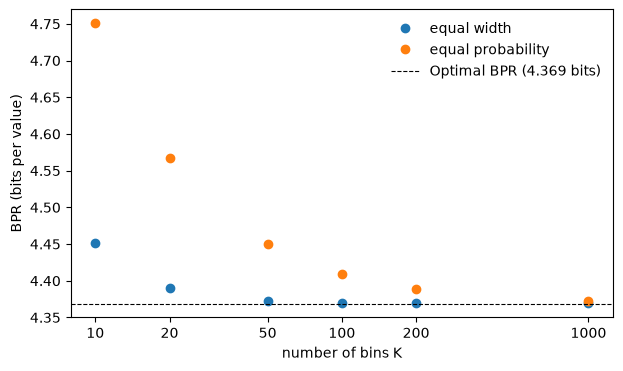

In [24]:
# 1b. BIN COUNT AND SPACING: COMPUTING BPR
#
# BPR is computed for a true value V based on the probability assigned to the bin that contains V and its width:
#
#     bits = -log2(probability of bin k / width of bin k)
#
# High probability assigned to a narrow range that contains V results in low BPR.
#
# For this demonstration, remember that each bin probability is set by an oracle to be the expectation for values in its range.
# Therefore, we can compare BPR due to bin choices alone, not model fit/capacity.
#
# The dashed line is the minimum theoretical BPR for this distribution:
# 0.5 * log2(2 * pi * e * sd^2) = 4.369 bits for sd = 5.
# 
# Infinite bins can approach this score. This is also equivalent to the differential entropy of the distribution.


# This is computed as the average bits per value for each bin layout.
# Here we compute it exactly instead of drawing samples and computing it via simulation
def average_bits(edges):
    prob = np.diff(true_dist.cdf(edges))
    width = np.diff(edges)
    return np.sum(prob * -np.log2(prob / width))


bpr_equal_width = [average_bits(equal_width_edges(K)) for K in Ks]
bpr_equal_prob = [average_bits(equal_probability_edges(K)) for K in Ks]
best = true_dist.entropy() / np.log(2)                 # score of the true curve itself

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Ks, bpr_equal_width, "o", color="C0", label="equal width")
ax.plot(Ks, bpr_equal_prob, "o", color="C1", label="equal probability")
ax.axhline(best, color="black", ls="--", lw=0.8, label=f"Optimal BPR ({best:.3f} bits)")
ax.set_xscale("log")
ax.set_xticks(Ks, [str(K) for K in Ks])
ax.minorticks_off()
ax.set_xlabel("number of bins K")
ax.set_ylabel("BPR (bits per value)")
ax.legend(frameon=False)
plt.show()

# Key points:
# - Both bin strategies approach the optimal BPR with higher bin counts 
# - Equal bin width approaches the optimal faster. Equal probabilitty has wide
#   bins for the tails leading to poor approximation when bin probabilities are
#   perfect and unbiased


In [25]:
# 1c. BIN COUNT AND SPACING: THE SAME CALCULATION IN DBTOKEN
#
# The formula in 1b is what dbtoken.metrics.bits_per_row computes for a binned
# model. Here we run the library end to end for K = 20:
#   1) simulate 20,000 values from the true distribution (one lab row each)
#   2) tokenize them with DBTokenizer, using the bin layouts from 1a
#   3) build a fake model whose bin predictions are the true bin probabilities
#   4) score the fake model with dbtoken.metrics.bits_per_row
#
# The fake model is a lookup table: given the current token, it returns the
# probabilities of the next token. Structural tokens (start, class, concept,
# end) are predicted with probability 1, so they cost 0 bits. After the concept
# token it predicts the bin, using the true probability of each bin. All bits
# therefore come from the numeric value.
#
# The library treats the first and last bins as open-ended tails (see section
# 7). We hand it all 21 edges of each layout, including 20 and 80, so it sees
# our 20 bins plus two empty tails beyond 6 standard deviations that never
# occur.

import contextlib, io, warnings
from datetime import datetime
import polars as pl
import torch
from dbtoken import DBTokenizer
from dbtoken.metrics import bits_per_row

K = 20
values = true.rvs(20_000, random_state=1)            # the values that "actually occurred"
df = pl.DataFrame({
    "id": np.arange(len(values)),                     
    "time": [datetime(2024, 1, 1)] * len(values),
    "class": "lab",
    "text_value": "glucose",
    "numeric_value": values,
})


# the oracle model. all BPR differences come from numeric strategy not models
class LookupModel(torch.nn.Module):
    """Fake model: next-token log-probabilities looked up from the current token."""
    def __init__(self, table):
        super().__init__()
        self.table = table

    def forward(self, idx):
        return self.table[idx], None


def dbtoken_bpr(edges):

    # construct the tokenizer object to be able to use the built-in function
    tok = DBTokenizer(text_mode_default="concept", num_type="discrete", n_bins=K + 1)
    with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():
        warnings.simplefilter("ignore")
        tok.train(df)
    tok.numeric_params[("lab", "glucose")]["edges"] = list(edges)     # the 1a layout
    ids, _ = tok.encode(df)

    v = tok.vocab
    table = torch.full((len(v), len(v)), -50.0)       # log-probability of ~0
    table[v["<|sos|>"], v["<|lab|>"]] = 0.0           # log-probability of 1
    table[v["<|lab|>"], v["glucose"]] = 0.0
    table[v["<|eos|>"], v["<|sos|>"]] = 0.0
    bin_prob = np.diff(true.cdf(np.concatenate([[-np.inf], edges, [np.inf]])))
    for k, p in enumerate(bin_prob):                  # bins: tail, our 20 bins, tail
        table[v["glucose"], v[f"<|Q{k}|>"]] = np.log(p)
        table[v[f"<|Q{k}|>"], v["<|eos|>"]] = 0.0
    ids = torch.tensor(ids).unsqueeze(0)

    # apply the real bits per row function on the data
    result = bits_per_row(LookupModel(table), tok, [(ids[:, :-1], ids[:, 1:])])
    return result["numeric_bpr"], tok.decode(ids[0, :10].tolist())

# demonstrate the formula from above
def formula_1b(edges):
    prob = np.diff(true.cdf(edges))
    width = np.diff(edges)
    k = np.digitize(values, edges) - 1                # which bin each value fell in
    return np.mean(-np.log2(prob[k] / width[k]))


print(f"{'K = 20':<20}{'1b exact':>10}{'1b on sim':>10}{'dbtoken':>10}")
for name, make_edges in [("equal width", equal_width_edges),
                         ("equal probability", equal_probability_edges)]:
    edges = make_edges(K)
    lib, first_tokens = dbtoken_bpr(edges)
    print(f"{name:<20}{average_bits(edges):10.4f}{formula_1b(edges):10.4f}{lib:10.4f}")

# Key points:
# - "1b on sim" and "dbtoken" score the same 20,000 values and agree to within rounding error
# - Both differ slightly from "1b exact" becuase of simulation variation

K = 20                1b exact 1b on sim   dbtoken
equal width             4.3903    4.3899    4.3899
equal probability       4.5666    4.5655    4.5655


In [26]:
# 2. CONTINUOUS VALUES
#
# Continuous value tokenization predicts a parameterized distribution (i.e.
# probability density) of values instead of probablity masses across discrete
# bins. We can therefore directly compute:
#
#     bits = -log2(probability density for value v)
#
# Here the model predicts the true curve (mean 50, sd 5), so it should land
# exactly on the dashed line from section 2. We check this two ways: by
# averaging over many simulated values, and with the exact formula.

model_dist = stats.norm(50, 5)                  # the model's prediction (here: matches the true value dist)

values = true_dist.rvs(100_000, random_state=0) # values that "actually occurred"
bits = -np.log2(model_dist.pdf(values))         # bits for to each true value value

print(f"average over 100,000 simulated values:  {bits.mean():.3f} bits")
print(f"exact, 0.5 * log2(2 pi e sd^2):          {0.5 * np.log2(2 * np.pi * np.e * 5**2):.3f} bits")
print(f"equal-width bins, K = 1000 (section 2): {average_bits(equal_width_edges(1000)):.3f} bits")

# Key point:
# - The simulated average (4.365 bits) agrees with the exact value (4.369 bits)
#   to within simulation noise.

average over 100,000 simulated values:  4.365 bits
exact, 0.5 * log2(2 pi e sd^2):          4.369 bits
equal-width bins, K = 1000 (section 2): 4.369 bits


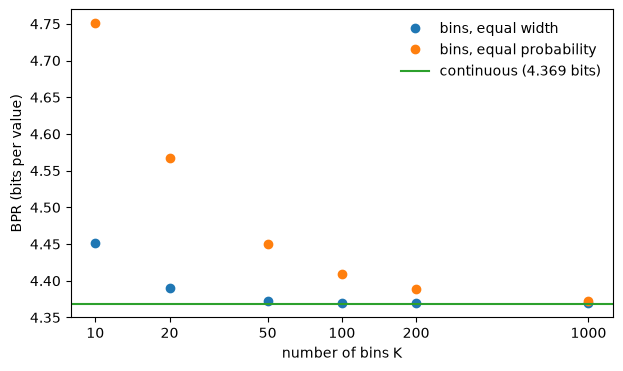

    K   equal width   equal prob.   (extra bits per value vs continuous)
   10         0.082         0.381
   20         0.021         0.198
   50         0.003         0.081
  100         0.001         0.041
  200         0.000         0.020
 1000         0.000         0.004


In [ ]:
# CONTINUOUS VALUES AND DISCRETE VALUES
#
# Just as we expected infinite bins to approximate the true differential
# entropy, we expect the continuous representation to be this value as well.

def average_bits_continuous(predicted):
    bits_at = lambda v: true_dist.pdf(v) * -np.log2(predicted.pdf(v)) # how often we expect v * its surprise in bits
    return quad(bits_at, LO, HI)[0]


bpr_continuous = average_bits_continuous(stats.norm(50, 5))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Ks, bpr_equal_width, "o", color="C0", label="bins, equal width")
ax.plot(Ks, bpr_equal_prob, "o", color="C1", label="bins, equal probability")
ax.axhline(bpr_continuous, color="C2", label=f"continuous ({bpr_continuous:.3f} bits)")
ax.set_xscale("log")
ax.set_xticks(Ks, [str(K) for K in Ks])
ax.minorticks_off()
ax.set_xlabel("number of bins K")
ax.set_ylabel("BPR (bits per value)")
ax.legend(frameon=False)
plt.show()

print(f"{'K':>5}  {'equal width':>12}  {'equal prob.':>12}   (extra bits per value vs continuous)")
for K, w, p in zip(Ks, bpr_equal_width, bpr_equal_prob):
    print(f"{K:>5}  {w - bpr_continuous:12.3f}  {p - bpr_continuous:12.3f}")

# Key points:
# - At K = 10, the binned predictions cost 0.08 bits (equal width) and 0.38 bits
#   (equal probability) per value more than the continuous model.
# - This captures fundamental BPR differences between approaches under oracle
#   conditions for the predictive model. it does not mean continuous is always better in practice

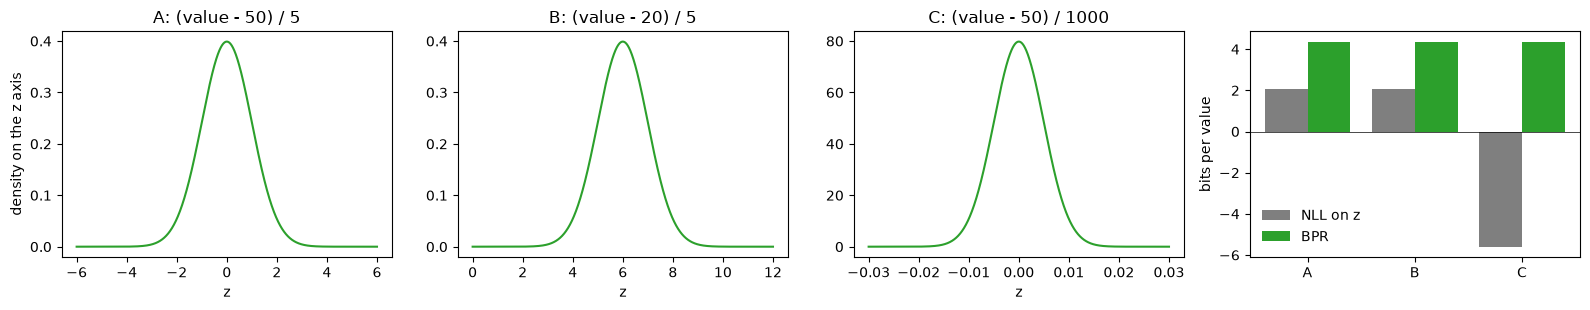

A: (value - 50) / 5       NLL(z-scale)   2.047 bits   BPR 4.369 bits
B: (value - 20) / 5       NLL(z-scale)   2.047 bits   BPR 4.369 bits
C: (value - 50) / 1000    NLL(z-scale)  -5.597 bits   BPR 4.369 bits


In [ ]:
# Why Negative-log liklihood is not adquate for comapring continuous models in
# practice.
# 
# In practice, continuous models rarely predict the raw value due to mumerical
# stability. The tokenizer first rescales it, z = (value - center) / stretch,
# and the model predicts this transformed z. If BPR were calculated on the NLL
# of this distribution it would be incorrect.

# Consider an adjustment that divided all true values by a large number such
# that every true value was (-0.1,0.1). The model could easily achieve a high
# negative log liklihood by just predicting (-0.1, 0.1) in z space, giving the
# illusion of a good fit.
#
#
# BPR adjusts for this stretch by converting back to the original axis using the
# JACOBIAN of the scaling function (|dz/dvalue|)
#
#     BPR = NLL(z)  - log2 |dz/dvalue|
#
# For z = (value - center) / stretch, one unit in v becomes 1/stretc units in z.
# The centering does not affect dz/dvalue so does not contribute.
#
# For non-linear rescalings, the degree of stretch varies along the axis, so the
# correction depends on the vale. For example a log transform z = log(value)
# compresses large values more than small ones. The DBToken library computes
# this correction for each scaling method that it supports.
#
# Below, the same prediction (mean 50, sd 5) is expressed through three
# rescalings: 
#   - A: z = (value - 50) / 5, model predicts mean 0, sd 1
#   - B: z = (value - 20) / 5, model predicts mean 6, sd 1
#   - C: z = (value - 50) / 1000 model predicts mean 0, sd 0.005

rescalings = {
    "A: (value - 50) / 5":    dict(center=50, stretch=5),
    "B: (value - 20) / 5":    dict(center=20, stretch=5),
    "C: (value - 50) / 1000": dict(center=50, stretch=1000),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
results = {}
for ax, (name, r) in zip(axes, rescalings.items()):
    c, st = r["center"], r["stretch"]
    on_z = stats.norm((50 - c) / st, 5 / st)          # the same prediction, on the z axis
    nll = quad(lambda v: true_dist.pdf(v) * -np.log2(on_z.pdf((v - c) / st)), LO, HI)[0]
    bpr = nll + np.log2(st)
    results[name] = (nll, bpr)

    z = (x - c) / st
    ax.plot(z, on_z.pdf(z), color="C2")
    ax.set_title(f"{name}")
    ax.set_xlabel("z")
axes[0].set_ylabel("density on the z axis")

names = list(results)
pos = np.arange(len(names))
axes[3].bar(pos - 0.2, [results[n][0] for n in names], 0.4, color="C7", label="NLL on z")
axes[3].bar(pos + 0.2, [results[n][1] for n in names], 0.4, color="C2", label="BPR")
axes[3].axhline(0, color="black", lw=0.5)
axes[3].set_xticks(pos, ["A", "B", "C"])
axes[3].set_ylabel("bits per value")
axes[3].legend(frameon=False)
fig.tight_layout()
plt.show()

for name, (nll, bpr) in results.items():
    print(f"{name:<24}  NLL(z-scale) {nll:7.3f} bits   BPR {bpr:.3f} bits")

# Key points:
# - A vs B: moving the center only slides the curve along the axis. Its height
#   is unchanged.
# - A vs C: scaling the axis 200 times more makes the curve 200 times taller,
#   changing the NLL computed at each point (goes negative)
# - While NLL is comparabel among methods with the same scale factor only, BPR
#   is comparable across different rescalings.

Bimodal (peaks at 40 and 60):  Gaussian 5.530   bins K=10 5.341   bins K=100 5.282   true curve 5.281  (bits per value)
Student-t (heavy tails):  Gaussian 4.859   bins K=10 4.847   bins K=100 4.791   true curve 4.790  (bits per value)


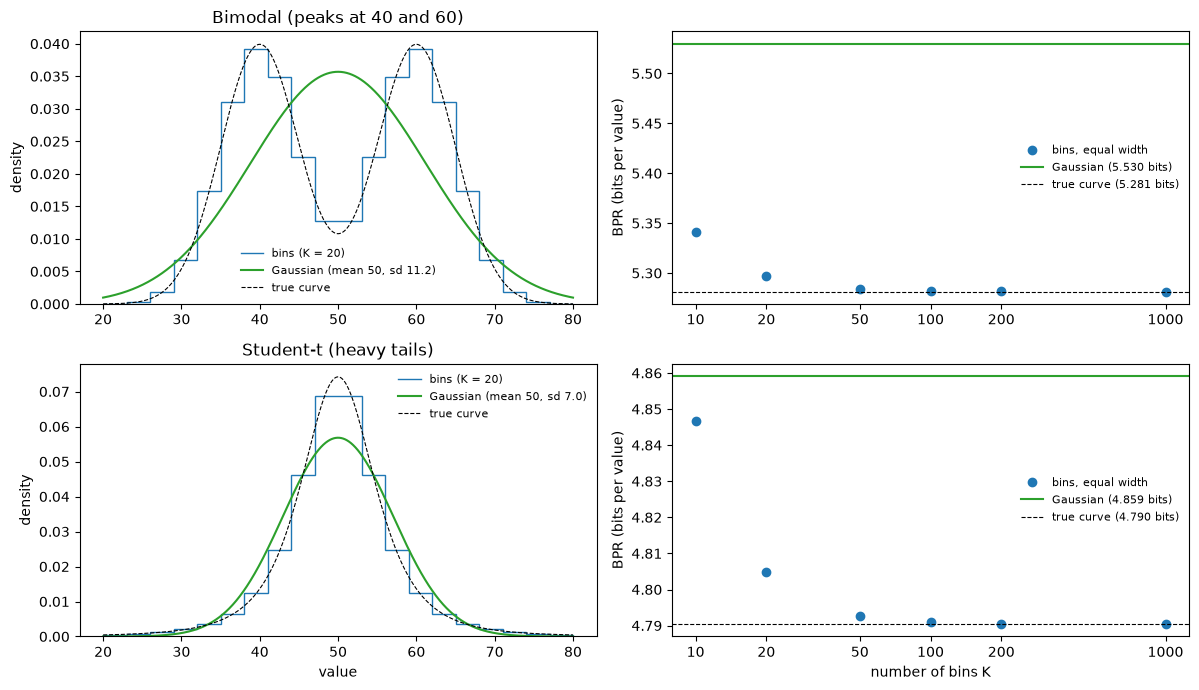

In [ ]:
# 6. WHEN THE TRUTH IS NOT A BELL CURVE
#
# For all prior examples, the true valueus were gaussian distributed, so the
# continuous representation was perfect. While a gaussian is a reasonable
# expectation after conditioining on context (it is a maximum entropy
# distribution for a given mean and variance), real measurements often deviate
# from this ideal. there still may be deviations from a normal distribution in
# the true distribution of future values. 
# 
# Here we demonstrate discrete vs. continuous numeric representations for
# bimodal and heavy tailed distributions.
#
# All numeric representations are still fit to the ground truth via an oracle.
#
# we compute numeric BPR for both discrete (binned) and continuous (Gaussian)
# representations for each of these distirbutions


from types import SimpleNamespace


def restrict(pdf, cdf):
    inside = cdf(HI) - cdf(LO)
    return SimpleNamespace(pdf=lambda v: pdf(v) / inside,
                           cdf=lambda v: (cdf(v) - cdf(LO)) / inside)

def expected_bits(truth, model_pdf):
    return quad(lambda v: truth.pdf(v) * -np.log2(model_pdf(v)), LO, HI, limit=200)[0]

def binned_bits(truth, edges):
    prob = np.diff(truth.cdf(edges))
    width = np.diff(edges)
    return np.sum(prob * -np.log2(prob / width))

left, right, heavy = stats.norm(40, 5), stats.norm(60, 5), stats.t(3, 50, 5)
truths = {
    "Bimodal (peaks at 40 and 60)": restrict(lambda v: 0.5 * left.pdf(v) + 0.5 * right.pdf(v),
                                             lambda v: 0.5 * left.cdf(v) + 0.5 * right.cdf(v)),
    "Student-t (heavy tails)": restrict(heavy.pdf, heavy.cdf),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, (name, truth) in zip(axes, truths.items()):
    mean = quad(lambda v: v * truth.pdf(v), LO, HI)[0]
    sd = np.sqrt(quad(lambda v: (v - mean) ** 2 * truth.pdf(v), LO, HI)[0])
    gaussian = stats.norm(mean, sd)                       # best single bell curve

    bins = [binned_bits(truth, equal_width_edges(K)) for K in Ks]
    gauss_bits = expected_bits(truth, gaussian.pdf)
    best = expected_bits(truth, truth.pdf)                # knowing the true curve exactly

    edges20 = equal_width_edges(20)
    row[0].stairs(np.diff(truth.cdf(edges20)) / np.diff(edges20), edges20, color="C0",
                  label="bins (K = 20)")
    row[0].plot(x, gaussian.pdf(x), color="C2", label=f"Gaussian (mean {mean:.0f}, sd {sd:.1f})")
    row[0].plot(x, truth.pdf(x), color="black", ls="--", lw=0.8, label="true curve")
    row[0].set_title(name)
    row[0].set_ylabel("density")
    row[0].legend(frameon=False, fontsize=8)

    row[1].plot(Ks, bins, "o", color="C0", label="bins, equal width")
    row[1].axhline(gauss_bits, color="C2", label=f"Gaussian ({gauss_bits:.3f} bits)")
    row[1].axhline(best, color="black", ls="--", lw=0.8, label=f"true curve ({best:.3f} bits)")
    row[1].set_xscale("log")
    row[1].set_xticks(Ks, [str(K) for K in Ks])
    row[1].minorticks_off()
    row[1].set_ylabel("BPR (bits per value)")
    row[1].legend(frameon=False, fontsize=8)

    print(f"{name}:  Gaussian {gauss_bits:.3f}   bins K=10 {bins[0]:.3f}   "
          f"bins K=100 {bins[3]:.3f}   true curve {best:.3f}  (bits per value)")
axes[1, 0].set_xlabel("value")
axes[1, 1].set_xlabel("number of bins K")
fig.tight_layout()
plt.show()

# Key points:
# - Bimodal: the normal distribution that maximizes likelihood has a peak at 50
#   where values are actually quite rare. As a result the discrete case
#   significantly outperforms it.
# - Heavy Tails: the normal distribution shares the same center as the student-t
#   but misallocates probability in the tails. Here the equal bin width discrete
#   reprentation outperforms it although the penalty is smaller

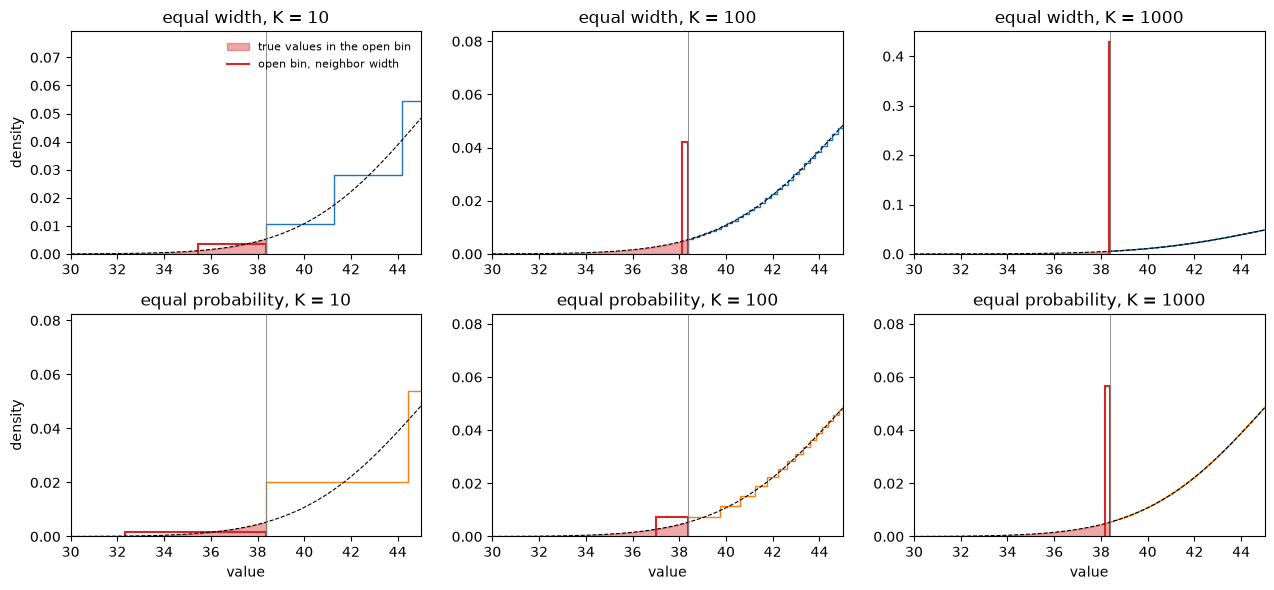

true density at the edge (38.4): 0.0053
equal width        K =   10: neighbor width 2.908, assumed density in the open bin 0.0034
equal width        K =  100: neighbor width 0.237, assumed density in the open bin 0.0421
equal width        K = 1000: neighbor width 0.023, assumed density in the open bin 0.4290
equal probability  K =   10: neighbor width 6.058, assumed density in the open bin 0.0017
equal probability  K =  100: neighbor width 1.363, assumed density in the open bin 0.0073
equal probability  K = 1000: neighbor width 0.177, assumed density in the open bin 0.0566


In [ ]:
# 3a. EXTREME VALUES: OPEN-ENDED BINS AND CLIPPING
#
# Binned tokenizers place their outermost edges at fixed locatioins for example
# at the 1st and 99th percentiles. Every value below the first edge falls in the
# bottom bin (-inf, 38.4) and every value above the last edge falls in the top
# bin [61.6, inf).
#
# An open-ended bin has no width, so its probability mass cannot be converted to
# a density by dividing by the bin width. There are two ways to handle extreme
# values:
#   1) neighbor width: the open-ended bin uses the width of its neighboring bin.
#      This assumes the 1% tail mass is spread evenly over a range the size of
#      the neighbor.
#   2) clipping: extreme values are treated as separate probability mass above
#      and below the clip location. This can apply to both discrete and
#      continuous methods.
#
# Continuous predictions have no bins. Without clipping, an extreme value is
# scored by the density at its value. With clipping, the value is recorded at
# the clip point and can be scored either by the density at the clip point or by
# the probability mass of the tail.
#
# It is critical that clipping points are the same for continuous and discrete
# represenations across all bin numbers. Because clipped tails are being
# evaluated as probability masses, they no longer contain information about the
# precise values within the tails. Consider this: clipping for a discrete model
# is set to 49.9% and 50.1%. A model would be rewarded for predictions in the
# open ended bins oneither side although there is almost no precision within
# those bins.
#
# Below is a visualization of the lower tail probability density and bin
# structure under the assumption that the open-ended bins use the neighbor
# width.

# outermost bin edges: 1st and 99th percentiles of the true value distribution
low, high = true_dist.ppf(0.01), true_dist.ppf(0.99)

# probability mass in each open-ended bin (0.01 each)
p_low, p_high = true_dist.cdf(low), true_dist.sf(high)

# K bins: 2 open-ended bins plus K - 2 bins between low and high
def bins_with_open_ends(K, layout):
    if layout == "equal width":
        edges = np.linspace(low, high, K - 1)
    else:
        edges = true_dist.ppf(np.linspace(0.01, 0.99, K - 1))
    prob = np.diff(np.concatenate([[0], true_dist.cdf(edges), [1]]))   # open, middle..., open
    return edges, prob


layouts = ["equal width", "equal probability"]
xt = np.linspace(30, 45, 1000)
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for (ax, K), layout in [((ax, K), layout) for layout, row in zip(layouts, axes)
                        for ax, K in zip(row, [10, 100, 1000])]:
    edges, prob = bins_with_open_ends(K, layout)
    width = np.diff(edges)
    neighbor_height = p_low / width[0]                 # assumed density in the open bin
    ax.fill_between(xt[xt <= low], true_dist.pdf(xt[xt <= low]), color="C3", alpha=0.4,
                    label="true values in the open bin")
    ax.stairs(prob[1:-1] / width, edges, color="C0" if layout == "equal width" else "C1", lw=1)
    ax.stairs([neighbor_height], [low - width[0], low], color="C3", lw=1.5,
              label="open bin, neighbor width")
    ax.plot(xt, true_dist.pdf(xt), color="black", lw=0.8, ls="--")
    ax.axvline(low, color="gray", lw=0.6)
    ax.set_xlim(30, 45)
    ax.set_title(f"{layout}, K = {K}")
for ax in axes[1]:
    ax.set_xlabel("value")
for ax in axes[:, 0]:
    ax.set_ylabel("density")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

print(f"true density at the edge ({low:.1f}): {true_dist.pdf(low):.4f}")
for layout in layouts:
    for K in [10, 100, 1000]:
        edges, prob = bins_with_open_ends(K, layout)
        w = edges[1] - edges[0]
        print(f"{layout:<18} K = {K:>4}: neighbor width {w:.3f}, "
              f"assumed density in the open bin {p_low / w:.4f}")

# Key points:
# - The open-ended bin always holds the same values, but the neighbor
#   width shrinks as K grows, so the assumed density keeps rising.

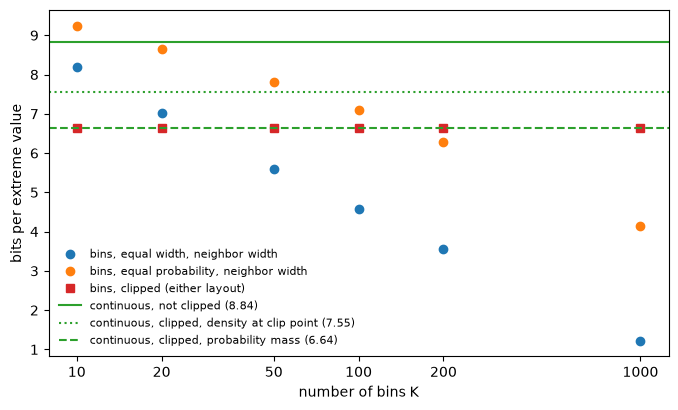

bits per extreme value
  bins, neighbor width             equal width  equal prob.
    K = 10                                8.18         9.24
    K = 20                                7.01         8.66
    K = 50                                5.60         7.82
    K = 100                               4.57         7.09
    K = 200                               3.55         6.28
    K = 1000                              1.22         4.14
  bins, clipped (any K, layout):    6.64
  continuous, not clipped:          8.84
  continuous, clipped, density:     7.55
  continuous, clipped, mass:        6.64


In [ ]:
# 3b. EXTREME VALUES: BPR
#
# Here we compute BPR only for the extreme values, i.e. the 1% of values in the
# bottom open-ended bin or clipping region (the top is symmetric). As before,
# bin probabilities and the continuous distribution come from the oracle.
#
#   bins, neighbor width:           -log2(0.01 / neighbor width), changes with K
#                                   and with the bin layout
#   bins, clipped:                  -log2(0.01) = 6.64
#   continuous, not clipped:        average -log2(density at the actual value)
#   continuous, clipped (density):  -log2(density at the clip point 38.4)
#   continuous, clipped (mass):     -log2(0.01) = 6.64
#
# "Not clipped" and "clipped" describe different outcomes ("V = 35.2" vs
# "V <= 38.4"), so their bits are not directly comparable. Models are only
# comparable when they are scored against the same outcome.

model_dist = stats.norm(50, 5)                    # oracle: matches the true value dist

# bins
bits_neighbor = {}
for layout in layouts:
    bits_neighbor[layout] = []
    for K in Ks:
        edges, prob = bins_with_open_ends(K, layout)
        bits_neighbor[layout].append(-np.log2(prob[0] / (edges[1] - edges[0])))
bits_bins_clipped = -np.log2(p_low)                # same for either layout

# continuous. Not clipped: average over the tail, weighted by the true density
# (quad integrates from -inf to the edge; dividing by p_low averages within the tail)
bits_cont_raw = quad(lambda v: true_dist.pdf(v) * -model_dist.logpdf(v) / np.log(2),
                     -np.inf, low)[0] / p_low
bits_cont_clip_density = -np.log2(model_dist.pdf(low))
bits_cont_clip_mass = -np.log2(model_dist.cdf(low))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(Ks, bits_neighbor["equal width"], "o", color="C0", label="bins, equal width, neighbor width")
ax.plot(Ks, bits_neighbor["equal probability"], "o", color="C1",
        label="bins, equal probability, neighbor width")
ax.plot(Ks, [bits_bins_clipped] * len(Ks), "s", color="C3", label="bins, clipped (either layout)")
ax.axhline(bits_cont_raw, color="C2", label=f"continuous, not clipped ({bits_cont_raw:.2f})")
ax.axhline(bits_cont_clip_density, color="C2", ls=":",
           label=f"continuous, clipped, density at clip point ({bits_cont_clip_density:.2f})")
ax.axhline(bits_cont_clip_mass, color="C2", ls="--",
           label=f"continuous, clipped, probability mass ({bits_cont_clip_mass:.2f})")
ax.set_xscale("log")
ax.set_xticks(Ks, [str(K) for K in Ks])
ax.minorticks_off()
ax.set_xlabel("number of bins K")
ax.set_ylabel("bits per extreme value")
ax.legend(frameon=False, fontsize=8)
plt.show()

print("bits per extreme value")
print(f"  {'bins, neighbor width':<32}{'equal width':>12}{'equal prob.':>13}")
for K, bw, bp in zip(Ks, bits_neighbor["equal width"], bits_neighbor["equal probability"]):
    print(f"  {'  K = ' + str(K):<32}{bw:12.2f}{bp:13.2f}")
print(f"  bins, clipped (any K, layout):   {bits_bins_clipped:5.2f}")
print(f"  continuous, not clipped:         {bits_cont_raw:5.2f}")
print(f"  continuous, clipped, density:    {bits_cont_clip_density:5.2f}")
print(f"  continuous, clipped, mass:       {bits_cont_clip_mass:5.2f}")

# Key points:
# - Neighbor width: bits for extreme values depend on K and on the bin layout.
#   Equal width goes from 8.18 (K = 10) to 1.22 (K = 1000); equal probability
#   from 9.24 to 4.14. Neither settles on the unclipped (8.84) or clipped (6.64)
#   value, and the narrower the neighbor, the cheaper extreme values look.
# - Clipping scored by probability mass: bins and continuous both give 6.64
#   bits at every K. They are scoring the same outcome.
# - Continuous clipped but scored by the density at the clip point (7.55) does
#   not match either outcome.
# - Extreme values are 2% of all values, so the effect on total BPR is 0.02 x
#   these differences, e.g. neighbor width at K = 1000 vs clipping:
#   0.02 x (6.64 - 1.22), about 0.11 bits (equal width), and
#   0.02 x (6.64 - 4.14), about 0.05 bits (equal probability).